# 01 · Oro de presión barométrica (Marco)
Sesión 3 · AireIQ · Equipo Novoa

**Pregunta descriptiva:** ¿cómo se comporta la presión barométrica en Juliaca a lo largo del día y entre días?

**Flujo:** plata de Frank (`data/silver/mediciones_1min`, ya limpia y promediada por minuto) → **oro de presión**:
1. Presión media por hora del día (la *marea atmosférica*).
2. Presión mínima, máxima y rango por día.
3. Cambio de la presión en 3 horas.

Reutilizo la plata del grupo en lugar de limpiar de nuevo: las reglas de limpieza (por ejemplo, descartar `gas_ohms = 0`, que es fallo del sensor) son las mismas para las cuatro variables.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

# Raíz del repositorio: sube hasta encontrar la carpeta data/
ROOT = Path.cwd().resolve()
while not (ROOT / "data").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SILVER = ROOT / "data" / "silver" / "mediciones_1min"     # la plata que genera el cuaderno 01 de Frank
GOLD   = ROOT / "data" / "gold"
assert SILVER.exists(), "Falta la plata: corre primero frank_iaq/notebooks/01_bronce_plata_oro.ipynb"

spark = (SparkSession.builder.appName("aireiq-marco-01").master("local[2]")
         .config("spark.driver.memory", "1g")
         .config("spark.sql.session.timeZone", "America/Lima")
         .config("spark.sql.shuffle.partitions", "8").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Raíz:", ROOT, "| Spark", spark.version)

Raíz: /home/jovyan/work | Spark 3.5.3


## 1 · La presión por minuto
La plata tiene un registro por minuto con el promedio de las lecturas válidas de ese minuto. La presión está en hectopascales (hPa). En Juliaca, a casi 4 000 m de altura, ronda los 645 hPa (al nivel del mar serían unos 1013).

In [2]:
s = (spark.read.parquet(str(SILVER))
     .select("minuto", "presion_hpa", "n_lecturas", "fecha")
     .withColumn("hora", F.hour("minuto")))
s.cache()
print(f"Minutos con datos: {s.count():,}")
s.select(F.min("minuto").alias("desde"), F.max("minuto").alias("hasta"),
         F.round(F.min("presion_hpa"), 2).alias("min_hPa"), F.round(F.avg("presion_hpa"), 2).alias("media_hPa"),
         F.round(F.max("presion_hpa"), 2).alias("max_hPa")).show(truncate=False)

Minutos con datos: 2,863
+-------------------+-------------------+-------+---------+-------+
|desde              |hasta              |min_hPa|media_hPa|max_hPa|
+-------------------+-------------------+-------+---------+-------+
|2026-10-21 23:52:00|2026-11-06 14:40:00|638.66 |645.35   |649.23 |
+-------------------+-------------------+-------+---------+-------+



## 2 · Marea atmosférica: presión media por hora del día
El sol calienta la atmósfera y la hace "respirar" dos veces al día: la presión sube y baja con un ritmo de 12 horas. Cerca del ecuador, como en Puno, este efecto se ve con claridad. Si el patrón existe en nuestros datos, un modelo que conozca la hora del día podrá anticiparlo.

In [3]:
media_total = s.agg(F.avg("presion_hpa")).first()[0]
por_hora = (s.groupBy("hora")
            .agg(F.count("*").alias("minutos"),
                 F.round(F.avg("presion_hpa"), 2).alias("presion_media"))
            .withColumn("desvio_hpa", F.round(F.col("presion_media") - F.lit(media_total), 2))
            .orderBy("hora"))
por_hora.write.mode("overwrite").parquet(str(GOLD / "presion_por_hora"))
por_hora.show(24)

+----+-------+-------------+----------+
|hora|minutos|presion_media|desvio_hpa|
+----+-------+-------------+----------+
|   0|    183|       646.51|      1.16|
|   1|    132|       646.13|      0.78|
|   2|    119|       645.93|      0.58|
|   3|    135|       645.69|      0.34|
|   4|     84|        646.1|      0.75|
|   5|    101|        646.5|      1.15|
|   6|     76|       647.23|      1.88|
|   7|     58|       648.13|      2.78|
|   8|     91|       646.59|      1.24|
|   9|    275|       645.36|      0.01|
|  10|    235|       644.25|      -1.1|
|  11|    147|       643.93|     -1.42|
|  12|     68|       641.92|     -3.43|
|  13|     87|       640.69|     -4.66|
|  14|     82|       641.96|     -3.39|
|  15|     65|       641.86|     -3.49|
|  17|     59|       642.16|     -3.19|
|  18|     60|       642.86|     -2.49|
|  19|     60|       643.36|     -1.99|
|  20|    142|       645.78|      0.43|
|  21|    180|       646.98|      1.63|
|  22|    218|       646.99|      1.64|


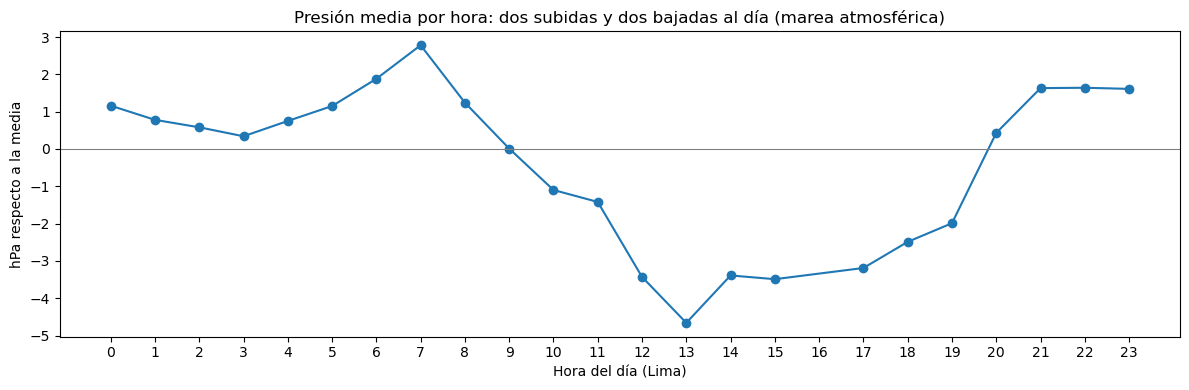

In [4]:
h = por_hora.toPandas()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(h["hora"], h["desvio_hpa"], marker="o")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(range(0, 24))
ax.set_xlabel("Hora del día (Lima)"); ax.set_ylabel("hPa respecto a la media")
ax.set_title("Presión media por hora: dos subidas y dos bajadas al día (marea atmosférica)")
plt.tight_layout(); plt.show()

**Cómo leer el gráfico:** cada punto es el promedio de todas las mediciones a esa hora. Sobre la línea gris la presión está más alta que su media; debajo, más baja. Se esperan máximos cerca de las 9 de la mañana y las 10 de la noche, y mínimos cerca de las 4 de la madrugada y las 4 de la tarde. Las horas con pocos minutos medidos son menos confiables.

## 3 · Presión por día
El **rango diario** (máxima menos mínima) es el indicador U1 de mi dimensión: cuánto se mueve la presión en un día.

In [5]:
por_dia = (s.groupBy("fecha")
           .agg(F.count("*").alias("minutos"),
                F.round(F.min("presion_hpa"), 2).alias("min_hpa"),
                F.round(F.avg("presion_hpa"), 2).alias("media_hpa"),
                F.round(F.max("presion_hpa"), 2).alias("max_hpa"))
           .withColumn("rango_hpa", F.round(F.col("max_hpa") - F.col("min_hpa"), 2))
           .orderBy("fecha"))
por_dia.write.mode("overwrite").parquet(str(GOLD / "presion_por_dia"))
por_dia.show(40, truncate=False)

+----------+-------+-------+---------+-------+---------+
|fecha     |minutos|min_hpa|media_hpa|max_hpa|rango_hpa|
+----------+-------+-------+---------+-------+---------+
|2026-10-21|5      |647.32 |647.33   |647.35 |0.03     |
|2026-10-22|768    |642.06 |647.47   |649.23 |7.17     |
|2026-10-23|10     |648.16 |648.2    |648.26 |0.1      |
|2026-10-28|195    |646.12 |646.65   |647.0  |0.88     |
|2026-10-29|624    |641.57 |644.54   |646.39 |4.82     |
|2026-10-30|233    |638.66 |641.44   |642.89 |4.23     |
|2026-10-31|46     |640.98 |641.79   |642.43 |1.45     |
|2026-11-01|374    |642.11 |644.64   |646.6  |4.49     |
|2026-11-05|102    |646.28 |646.83   |647.3  |1.02     |
|2026-11-06|506    |640.37 |644.93   |646.78 |6.41     |
+----------+-------+-------+---------+-------+---------+



## 4 · Cambio de la presión en 3 horas
Para cada minuto busco la presión 180 minutos después. Si ese minuto no tiene dato, la fila se descarta (no se inventan valores). En meteorología, la **tendencia barométrica de 3 horas** se usa para anticipar cambios de tiempo: una caída fuerte puede anunciar lluvia o tormenta.

Minutos con dato 3 horas después: 1,171
Cambio en 3 h · p5 = -2.83 hPa | mediana = -0.20 hPa | p95 = 2.29 hPa


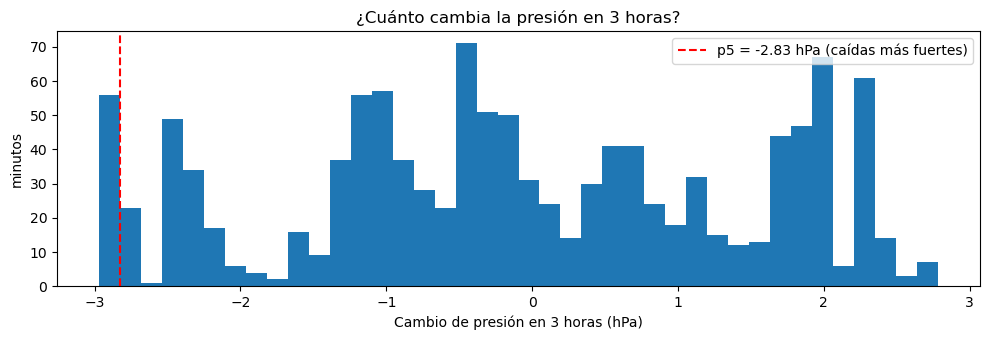

In [6]:
despues = s.select((F.col("minuto") - F.expr("INTERVAL 180 MINUTES")).alias("minuto"),
                   F.col("presion_hpa").alias("presion_3h"))
cambio = (s.join(despues, "minuto")
           .withColumn("cambio_3h", F.col("presion_3h") - F.col("presion_hpa")))
print(f"Minutos con dato 3 horas después: {cambio.count():,}")
p5, p50, p95 = cambio.approxQuantile("cambio_3h", [0.05, 0.5, 0.95], 0.001)
print(f"Cambio en 3 h · p5 = {p5:.2f} hPa | mediana = {p50:.2f} hPa | p95 = {p95:.2f} hPa")

c = cambio.select("cambio_3h").toPandas()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(c["cambio_3h"], bins=40)
ax.axvline(p5, color="red", ls="--", label=f"p5 = {p5:.2f} hPa (caídas más fuertes)")
ax.set_xlabel("Cambio de presión en 3 horas (hPa)"); ax.set_ylabel("minutos"); ax.legend()
ax.set_title("¿Cuánto cambia la presión en 3 horas?")
plt.tight_layout(); plt.show()

**Cómo leer el histograma:** cada barra cuenta cuántas veces la presión cambió esa cantidad en 3 horas. A la izquierda de la línea roja está el 5 % de las caídas más fuertes del periodo. Ese límite es el que uso después para la alerta.

## 5 · Verificación e indicadores U1

In [7]:
d = por_dia.filter(F.col("minutos") >= 600)      # solo días con al menos 10 horas medidas
rango_medio = d.agg(F.avg("rango_hpa")).first()[0]
amplitud = h["desvio_hpa"].max() - h["desvio_hpa"].min()
print("Capas  · plata:", s.count(), "minutos | oro por hora:", spark.read.parquet(str(GOLD / "presion_por_hora")).count(),
      "filas | oro por día:", spark.read.parquet(str(GOLD / "presion_por_dia")).count(), "filas")
print(f"Indicador U1 · rango diario medio (días con 10 h o más): {rango_medio:.2f} hPa en {d.count()} días")
print(f"Amplitud de la marea (máximo − mínimo del perfil por hora): {amplitud:.2f} hPa")

Capas  · plata: 2863 minutos | oro por hora: 23 filas | oro por día: 10 filas
Indicador U1 · rango diario medio (días con 10 h o más): 6.00 hPa en 2 días
Amplitud de la marea (máximo − mínimo del perfil por hora): 7.44 hPa


**Siguiente:** `02_presion_modelos.ipynb` usa la hora del día para predecir la presión dentro de 1 y 3 horas, y la compara con la persistencia.